# GCH / HCG overlay profiles with SEPARATE y-axes

Reproduces the **original** method from `scnomehic_paper/s2/s2.ipynb` (cell 14:
`plot_dual_axis_ctcf_noTSS` / `plot_dual_axis_TSS_CGI`) for the **GM12878 pseudobulk**
NOMe tracks.

**Why not deepTools `plotProfile`:** it forces both marks onto ONE shared y-axis, so HCG
(~17-60%) gets squashed against GCH (~63-82%) and weak signals look flat. The original
instead loads the `computeMatrix` output in Python and uses `ax.twinx()` so each mark has
its **own** y-axis:

| mark | axis | color |
|---|---|---|
| GCH accessibility | LEFT | green |
| HCG DNA methylation | RIGHT | black |

**Inputs** — matrices already built by `plotCTCF_pseudobulk.sh` (job 7583116) and
`plotCGI_pseudobulk.sh` (job 7586934), both with the paper's parameters
(`--referencePoint center|TSS`, `-b/-a 2000`, `-bs 20`, `--skipZeros --averageTypeBins mean`).
Our matrices hold BOTH samples (and, for TSS, both region groups) in one file, so we split
columns via the header's `sample_boundaries` and rows via `group_boundaries` instead of
reading two separate files as the original did.

Figures are written next to the matrices and also shown inline.

In [1]:
# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

%matplotlib inline
import gzip
import json
import numpy as np
import matplotlib.pyplot as plt

S3 = WORK + '/analysis/s3'

CTCF_MAT = f'{S3}/analysis/ctcf/matrices/GCH_HCG.CTCFnoTSS.matrix.gz'
TSS_MAT  = f'{S3}/analysis/tss_cgi/matrices/GCH_HCG.TSS_CGI_vs_nonCGI.matrix.gz'
CTCF_FIG = f'{S3}/analysis/ctcf/figures'
TSS_FIG  = f'{S3}/analysis/tss_cgi/figures'

GCH_COLOR = 'green'   # accessibility -> LEFT axis
HCG_COLOR = 'black'   # methylation   -> RIGHT axis
print('paths set')

paths set


In [2]:
def load_matrix(path):
    """computeMatrix .gz -> (header_dict, values array). Same reader as s2.ipynb cell 14.

    Line 1 is '#' + JSON header; each later line is a region, with the first 6 columns
    being BED metadata and the rest the per-bin values (across ALL samples, concatenated).
    """
    with gzip.open(path, 'rt') as f:
        header = json.loads(f.readline().strip()[1:])
        values = []
        for line in f:
            if line.strip():
                parts = line.rstrip('\n').split('\t')
                values.append([np.nan if x in ('nan', 'NA', '') else float(x)
                               for x in parts[6:]])
    return header, np.array(values, dtype=float)


def profiles(header, arr, group_idx=0):
    """Split rows by region group and columns by sample -> (x, GCH profile, HCG profile, n).

    Mean profile is nanmean down the rows, exactly as the original did.
    """
    gb, sb = header['group_boundaries'], header['sample_boundaries']
    sub = arr[gb[group_idx]:gb[group_idx + 1]]
    gch = sub[:, sb[0]:sb[1]]   # sample 0
    hcg = sub[:, sb[1]:sb[2]]   # sample 1
    up, down = header['upstream'][0], header['downstream'][0]
    x = np.linspace(-up, down, gch.shape[1])
    with np.errstate(invalid='ignore'):
        return x, np.nanmean(gch, axis=0), np.nanmean(hcg, axis=0), sub.shape[0]

print('loaders defined')

loaders defined


In [3]:
def dual_axis_plot(x, prof_gch, prof_hcg, n_regions, xlabel, title, out_base=None):
    """GCH on the LEFT axis (green), HCG on the RIGHT axis (black) via twinx().

    Styling mirrors s2.ipynb cell 14: dashed grey line at the reference point and an
    n= label in the top-left corner.
    """
    fig, ax_left = plt.subplots(figsize=(6.8, 5))

    ax_left.plot(x, prof_gch, color=GCH_COLOR, linewidth=1.5)
    ax_left.set_ylabel('GCH accessibility', color=GCH_COLOR, fontsize=13)
    ax_left.tick_params(axis='y', labelcolor=GCH_COLOR)

    ax_right = ax_left.twinx()
    ax_right.plot(x, prof_hcg, color=HCG_COLOR, linewidth=1.5)
    ax_right.set_ylabel('HCG DNA methylation level', color=HCG_COLOR, fontsize=13)
    ax_right.tick_params(axis='y', labelcolor=HCG_COLOR)

    ax_left.axvline(0, linestyle='--', color='gray', linewidth=1)
    ax_left.set_xlabel(xlabel, fontsize=13)
    ax_left.set_title(title, fontsize=13)
    ax_left.text(0.02, 0.98, f'n={n_regions:,}', transform=ax_left.transAxes,
                 ha='left', va='top', fontsize=12)

    plt.tight_layout()
    if out_base:
        for ext in ('pdf', 'png'):
            plt.savefig(f'{out_base}.{ext}', dpi=300)
        print(f'saved -> {out_base}.pdf / .png')
    plt.show()
    print(f'n={n_regions:,}   GCH {np.nanmin(prof_gch):.1f}-{np.nanmax(prof_gch):.1f}%'
          f'   HCG {np.nanmin(prof_hcg):.1f}-{np.nanmax(prof_hcg):.1f}%')

print('plotter defined')

plotter defined


## 1. CTCF (noTSS)

GM12878 CTCF ChIP-seq optimal-IDR peaks with nearby-TSS peaks removed
(`...noTSS4kb.sort.bed`; the original figure labels this "no TSS within 2kb", i.e. a 4 kb
window = +/-2 kb). `--referencePoint center`.

samples: ['GCH (accessibility)', 'HCG (methylation)']


saved -> /gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/s3/analysis/ctcf/figures/GCH_HCG.CTCFnoTSS.dualaxis.pdf / .png


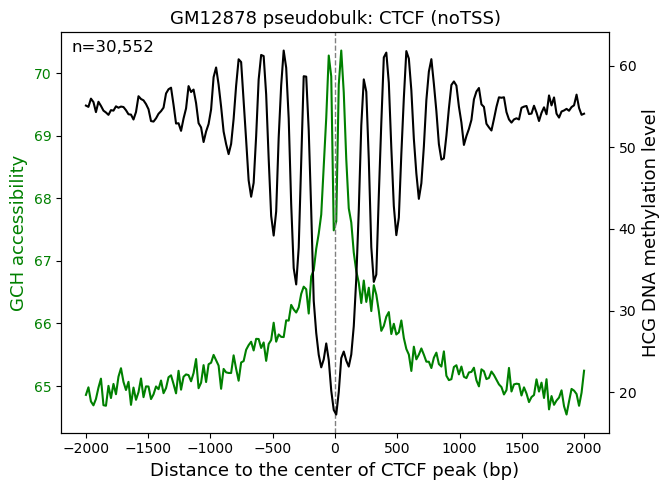

n=30,552   GCH 64.5-70.4%   HCG 17.3-61.9%


In [4]:
hdr_c, arr_c = load_matrix(CTCF_MAT)
print('samples:', hdr_c['sample_labels'])

x, pg, ph, n = profiles(hdr_c, arr_c, 0)
dual_axis_plot(x, pg, ph, n,
               'Distance to the center of CTCF peak (bp)',
               'GM12878 pseudobulk: CTCF (noTSS)',
               f'{CTCF_FIG}/GCH_HCG.CTCFnoTSS.dualaxis')

## 2. CGI TSS

gencode v45 TSS inside UCSC CpG islands. `--referencePoint TSS`.

groups: ['gencode.v45.TSS.UCSC_CGI.hg38.primary_assembly.gene_ensemble_id.sort.bed', 'gencode.v45.TSS.no_UCSC_CGI_plus_shore_2kb.hg38.primary_assembly.gene_ensemble_id.canonical.bed']


saved -> /gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/s3/analysis/tss_cgi/figures/GCH_HCG.TSS_CGI.dualaxis.pdf / .png


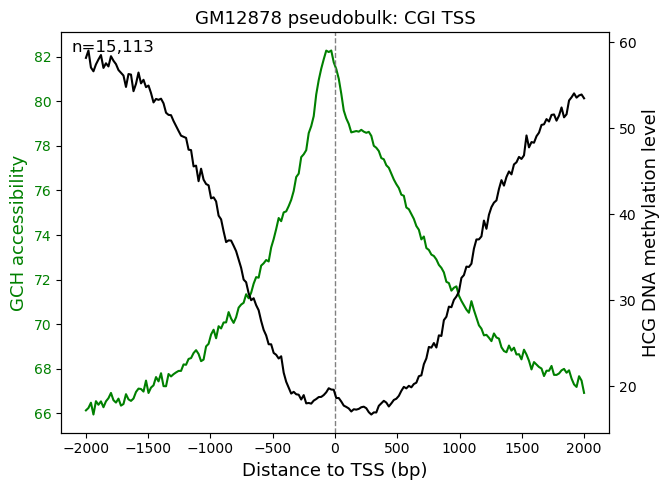

n=15,113   GCH 65.9-82.3%   HCG 16.7-59.0%


In [5]:
hdr_t, arr_t = load_matrix(TSS_MAT)
print('groups:', hdr_t['group_labels'])

x, pg, ph, n = profiles(hdr_t, arr_t, 0)   # group 0 = CGI TSS
dual_axis_plot(x, pg, ph, n,
               'Distance to TSS (bp)',
               'GM12878 pseudobulk: CGI TSS',
               f'{TSS_FIG}/GCH_HCG.TSS_CGI.dualaxis')

## 3. non-CGI TSS

gencode v45 TSS outside CpG islands *and* outside their 2 kb shores.
On its own y-axis the signal is clearly visible - on a shared axis it looks flat.

saved -> /gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/s3/analysis/tss_cgi/figures/GCH_HCG.TSS_nonCGI.dualaxis.pdf / .png


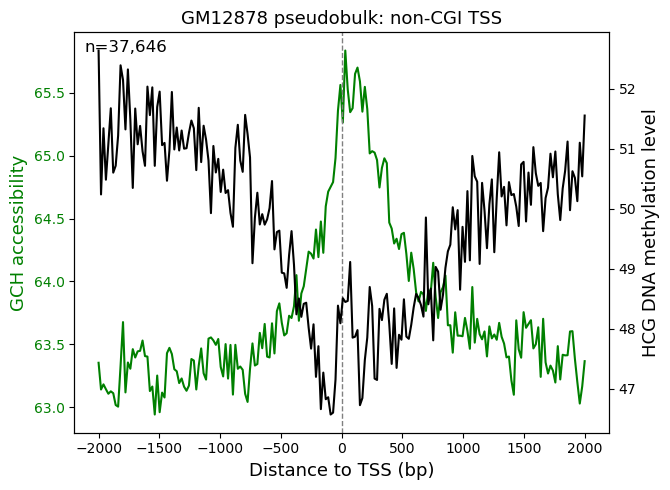

n=37,646   GCH 62.9-65.8%   HCG 46.6-52.6%


In [6]:
x, pg, ph, n = profiles(hdr_t, arr_t, 1)   # group 1 = non-CGI TSS
dual_axis_plot(x, pg, ph, n,
               'Distance to TSS (bp)',
               'GM12878 pseudobulk: non-CGI TSS',
               f'{TSS_FIG}/GCH_HCG.TSS_nonCGI.dualaxis')